In [1]:
import sys, pandas, matplotlib, xgboost, tensorflow

In [2]:
print(sys.version)

3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:11:32) [Clang 20.1.8 ]


In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import xgboost as xgb 
from sklearn.metrics import mean_absolute_error, mean_squared_error
from numpy.lib.stride_tricks import sliding_window_view
from pandas.tseries.holiday import USFederalHolidayCalendar
from tensorflow import keras

plt.rcParams["figure.figsize"]= (12,4)
keras.utils.set_random_seed(42)
print("Libraries loaded successfully.")


Libraries loaded successfully.


In [4]:
df=pd.read_csv("PJME_hourly.csv", index_col="Datetime", parse_dates=True)
df= df.sort_index()
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (145366, 1)


,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [5]:
import os
print(os.getcwd())      # folderul în care rulează notebook-ul
print(os.listdir())     # fișierele din acel folder

/Users/iuliaardelean/proiect_energie
['est_hourly.paruqet', 'PJMW_hourly.csv', 'energy.ipynb', 'pjm_hourly_est.csv', 'PJM_Load_hourly.csv', 'DAYTON_hourly.csv', 'NI_hourly.csv', 'PJME_hourly.csv', 'FE_hourly.csv', 'DOM_hourly.csv', 'EKPC_hourly.csv', 'DEOK_hourly.csv', 'DUQ_hourly.csv', '.vscode', 'AEP_hourly.csv', 'COMED_hourly.csv', '.conda']


In [6]:
print("Duplicate timestamps:", df.index.duplicated().sum())
df= df[~df.index.duplicated(keep="first")]

df= df.asfreq("h")
print("Missing Hours:", df["PJME_MW" ].isna().sum())
df["PJME_MW"]= df["PJME_MW"].interpolate()
df= df.rename (columns={"PJME_MW": "consumption"})
print("Period :", df.index.min(), "->", df.index.max())
print("Total Hours:", len(df))

Duplicate timestamps: 4
Missing Hours: 30
Period : 2002-01-01 01:00:00 -> 2018-08-03 00:00:00
Total Hours: 145392


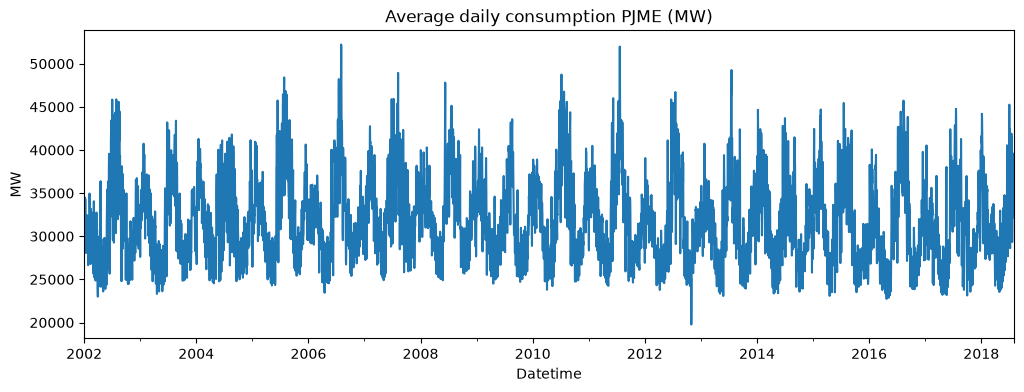

In [7]:
df["consumption"].resample("D").mean().plot(title="Average daily consumption PJME (MW)") 
plt.ylabel("MW")
plt.show()

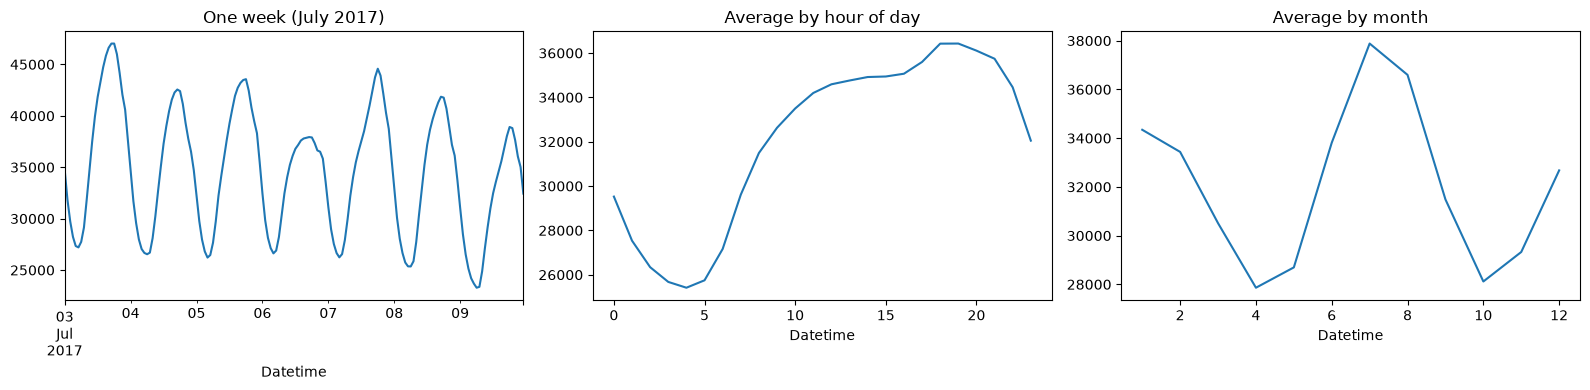

In [8]:
fig, axes= plt.subplots(1,3 , figsize=(16,4))
df.loc["2017-07-03":"2017-07-09", "consumption"].plot(ax=axes[0], title="One week (July 2017)")
df.groupby(df.index.hour)["consumption"].mean().plot(ax=axes[1], title="Average by hour of day")
df.groupby(df.index.month)["consumption"].mean().plot(ax=axes[2], title="Average by month")
plt.tight_layout()
plt.show()

In [9]:
TRAIN_END = "2013-12-31 23:00"
VAL_END = "2014-12-31 23:00"
train_mask=df.index <= TRAIN_END
val_mask=(df.index > TRAIN_END) & (df.index <= VAL_END)
test_mask=df.index > VAL_END

print("Train:" , df.index [train_mask].min().date(), "->", df.index [train_mask].max().date(), f"({train_mask.sum()} hours)")
print("Val:", df.index[val_mask].min().date(),"->", df.index [val_mask].max().date(), f"({val_mask.sum()} hours)" )
print("Test", df.index[test_mask].min().date() , "->", df.index[test_mask].max().date(), f"({test_mask.sum()} hours)")



Train: 2002-01-01 -> 2013-12-31 (105191 hours)
Val: 2014-01-01 -> 2014-12-31 (8760 hours)
Test 2015-01-01 -> 2018-08-03 (31441 hours)


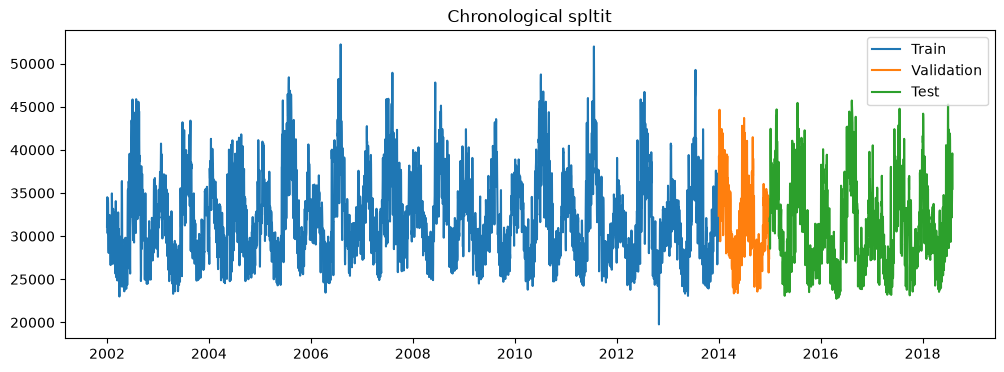

In [10]:
daily=df["consumption"].resample("D").mean()
plt.plot(daily[daily.index<= TRAIN_END], label="Train")
plt.plot(daily[(daily.index > TRAIN_END) & (daily.index <= VAL_END)], label= "Validation")
plt.plot(daily[daily.index > VAL_END] , label= "Test")
plt.legend()
plt.title("Chronological spltit")
plt.show()

In [11]:
def evaluate (y_true, y_pred, name):
    mae= mean_absolute_error(y_true, y_pred)
    rmse= np.sqrt(mean_squared_error(y_true, y_pred))
    mape=np.mean(np.abs((y_true - y_pred)/ y_true))*100
    print(f"{name:28s} MAE={mae:8.1f} MW | RMSE={rmse:8.1f} MW | MAPE={mape:5.2f}%")
    return{"Model": name , "MAE": mae, "RMSE": rmse, "MAPE %": mape}
results=[]
y_test=df.loc[test_mask, "consumption"]

In [12]:
features= pd.DataFrame(index=df.index)
features["hour"]=df.index.hour
features["day_of_week"]= df.index.dayofweek
features["month"]= df.index.month
features["day_of_year"]= df.index.dayofyear
features["is_weekend"]= (features["day_of_week"]>=5 ).astype(int)
holidays = USFederalHolidayCalendar().holidays(start=df.index.min(), end=df.index.max())
features["is_holiday"] = df.index.normalize().isin(holidays).astype(int)
features["lag_24"] = df["consumption"].shift(24)
features["lag_48"] = df["consumption"].shift(48)
features["lag_168"] = df["consumption"].shift(168)
features["mean_24h"] = df["consumption"].shift(24).rolling(24).mean()
features["mean_168h"] = df["consumption"].shift(24).rolling(168).mean()
features = features.dropna()
target = df["consumption"].loc[features.index]

print("Features:", list(features.columns))
features.head()


Features: ['hour', 'day_of_week', 'month', 'day_of_year', 'is_weekend', 'is_holiday', 'lag_24', 'lag_48', 'lag_168', 'mean_24h', 'mean_168h']


,hour,day_of_week,month,day_of_year,is_weekend,is_holiday,lag_24,lag_48,lag_168,mean_24h,mean_168h
Datetime,,,,,,,,,,,
2002-01-09 00:00:00,0,2,1,9,0,0,31187.0,28337.0,29563.0,33452.583333,32519.511905
2002-01-09 01:00:00,1,2,1,9,0,0,29445.0,26862.0,28121.0,33560.208333,32513.869048
2002-01-09 02:00:00,2,2,1,9,0,0,28670.0,25976.0,27437.0,33672.458333,32510.327381
2002-01-09 03:00:00,3,2,1,9,0,0,28375.0,25641.0,27301.0,33786.375000,32510.434524
2002-01-09 04:00:00,4,2,1,9,0,0,28542.0,25666.0,27533.0,33906.208333,32514.261905


In [13]:
train_f = features.index <= TRAIN_END
val_f = (features.index > TRAIN_END) & (features.index <= VAL_END)
test_f = features.index > VAL_END

X_train, y_train = features[train_f], target[train_f]
X_val, y_val = features[val_f], target[val_f]
X_test = features[test_f]

print("Shapes -> train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

Shapes -> train: (105000, 11) | val: (8760, 11) | test: (31441, 11)


# Antrenarea XGBoost

In [14]:
model_xgb= xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
model_xgb.fit(X_train,y_train, eval_set=[(X_val, y_val)], verbose=100)
print("Trees actually used:", model_xgb.best_iteration + 1)

[0]	validation_0-rmse:5892.44794
[100]	validation_0-rmse:2340.73039
[200]	validation_0-rmse:2298.44885
[300]	validation_0-rmse:2282.48322
[400]	validation_0-rmse:2274.55993
[500]	validation_0-rmse:2266.65696
[599]	validation_0-rmse:2269.38316
Trees actually used: 550


In [15]:
pred_xgb= model_xgb.predict(X_test)
results.append(evaluate(y_test.values, pred_xgb, "xgboost"))

xgboost                      MAE=  1793.1 MW | RMSE=  2421.1 MW | MAPE= 5.63%


In [16]:
pd.DataFrame(results).set_index("Model").round(2)

,MAE,RMSE,MAPE %
Model,,,
xgboost,1793.08,2421.13,5.63


In [17]:
baseline_pred = df["consumption"].shift(168)[test_mask]
results.append(evaluate(y_test.values, baseline_pred.values, "Baseline (last week)"))

pd.DataFrame(results).set_index("Model").round(2)

Baseline (last week)         MAE=  3400.2 MW | RMSE=  4645.3 MW | MAPE=10.54%


,MAE,RMSE,MAPE %
Model,,,
xgboost,1793.08,2421.13,5.63
Baseline (last week),3400.20,4645.30,10.54


In [18]:
WINDOW=168
HORIZON=24
values= df["consumption"].values.astype("float32")
train_mean= values[train_mask].mean()
train_std= values[train_mask].std()
values_scaled= (values- train_mean)/ train_std


In [19]:
windows= sliding_window_view(values_scaled, WINDOW)
n= len(values_scaled)
x_all= windows[: n -WINDOW- HORIZON +1 ]
y_all= values_scaled[WINDOW+HORIZON -1:]
t_all= df.index[WINDOW+HORIZON-1 :]

In [20]:
seq_train = t_all <= TRAIN_END
seq_val = (t_all > TRAIN_END) & (t_all <= VAL_END)
seq_test = t_all > VAL_END

X_tr, y_tr = x_all[seq_train][..., None], y_all[seq_train]
X_va, y_va = x_all[seq_val][..., None], y_all[seq_val]
X_te, y_te = x_all[seq_test][..., None], y_all[seq_test]

# check: same test hours as the other models
assert (t_all[seq_test] == y_test.index).all()
print("Shapes -> train:", X_tr.shape, "| val:", X_va.shape, "| test:", X_te.shape)

Shapes -> train: (105000, 168, 1) | val: (8760, 168, 1) | test: (31441, 168, 1)


In [21]:
model_lstm=keras.Sequential([
    keras.layers.Input(shape=(WINDOW, 1)),
    keras.layers.LSTM(32),
    keras.layers.Dense(1),
])
model_lstm.compile(optimizer="adam", loss="mse")
model_lstm.summary()
history=model_lstm.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=15, 
    batch_size=256,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=2,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
411/411 - 23s - 55ms/step - loss: 0.2498 - val_loss: 0.1971
Epoch 2/15
411/411 - 21s - 52ms/step - loss: 0.1803 - val_loss: 0.1897
Epoch 3/15
411/411 - 21s - 52ms/step - loss: 0.1829 - val_loss: 0.2072
Epoch 4/15
411/411 - 22s - 54ms/step - loss: 0.1781 - val_loss: 0.1993
Epoch 5/15
411/411 - 23s - 55ms/step - loss: 0.1723 - val_loss: 0.1913


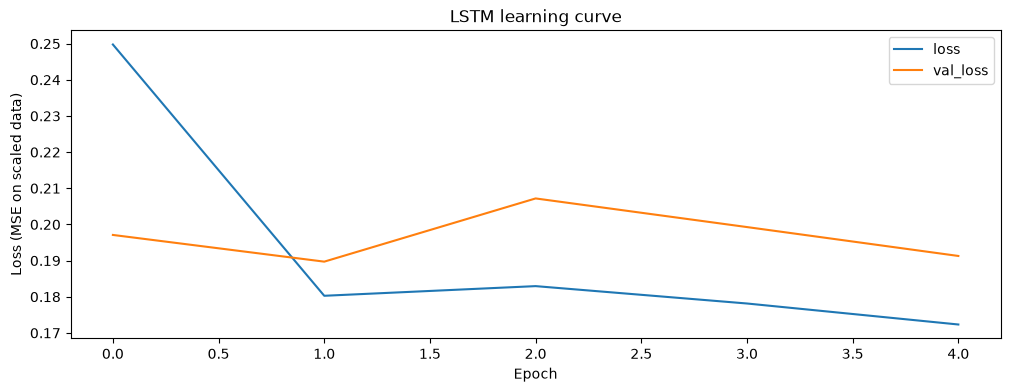

In [22]:
pd.DataFrame(history.history).plot(title="LSTM learning curve")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE on scaled data)")
plt.show()

In [23]:
pred_lstm= model_lstm.predict(X_te, batch_size=1024).ravel() * train_std + train_mean
results.append(evaluate(y_test.values, pred_lstm, "LSTM"))

pd.DataFrame(results).set_index("Model").round(2)

31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step
LSTM                         MAE=  2111.6 MW | RMSE=  2836.7 MW | MAPE= 6.72%


,MAE,RMSE,MAPE %
Model,,,
xgboost,1793.08,2421.13,5.63
Baseline (last week),3400.20,4645.30,10.54
LSTM,2111.62,2836.71,6.72


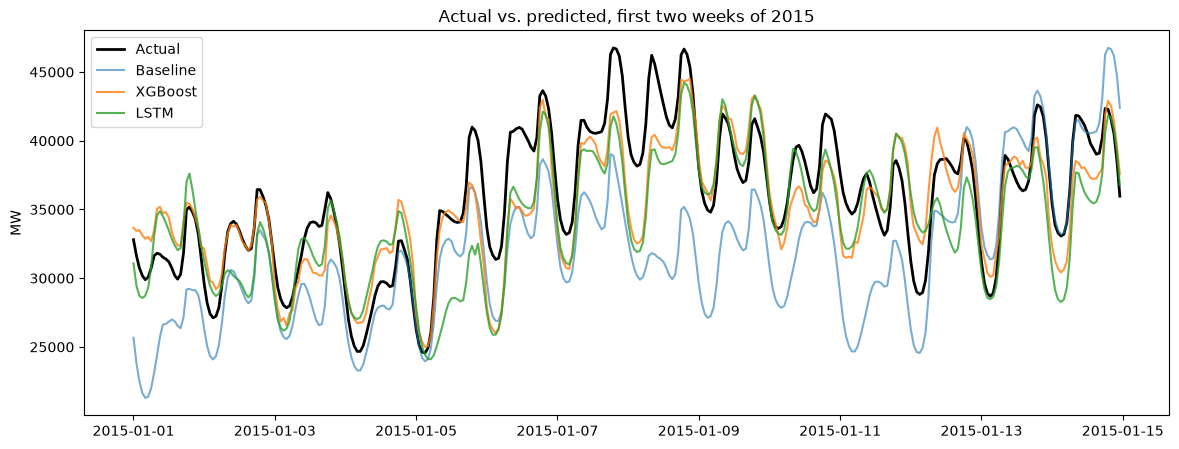

In [24]:
N = 24 * 14  # first 14 days of the test period
idx = y_test.index[:N]

plt.figure(figsize=(14, 5))
plt.plot(idx, y_test.values[:N], label="Actual", color="black", linewidth=2)
plt.plot(idx, baseline_pred.values[:N], label="Baseline", alpha=0.6)
plt.plot(idx, pred_xgb[:N], label="XGBoost", alpha=0.8)
plt.plot(idx, pred_lstm[:N], label="LSTM", alpha=0.8)
plt.legend()
plt.title("Actual vs. predicted, first two weeks of 2015")
plt.ylabel("MW")
plt.show()

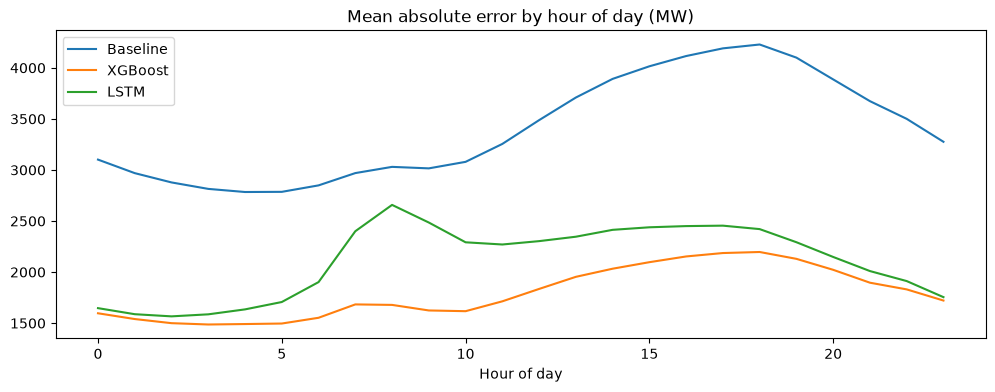

In [25]:
errors = pd.DataFrame({
    "Baseline": np.abs(y_test.values - baseline_pred.values),
    "XGBoost": np.abs(y_test.values - pred_xgb),
    "LSTM": np.abs(y_test.values - pred_lstm),
}, index=y_test.index)

errors.groupby(errors.index.hour).mean().plot(title="Mean absolute error by hour of day (MW)")
plt.xlabel("Hour of day")
plt.show()

## Conclusions

Day-ahead forecast of hourly demand (PJM East). Test set: Jan 2015 – Aug 2018 (31,441 hours).

| Model | MAE (MW) | RMSE (MW) | MAPE |
|---|---|---|---|
| Baseline (same hour last week) | 3,400 | 4,645 | 10.54% |
| LSTM | 2,112 | 2,837 | 6.72% |
| XGBoost | 1,793 | 2,421 | 5.63% |

- Both models clearly beat the baseline: XGBoost cut MAE by ~47%, the LSTM by ~38%.
- XGBoost was best on every metric, with ~15% lower MAE than the LSTM.
- Likely reason: XGBoost received calendar features (hour, weekday, holidays) and lags, while the LSTM only saw the raw consumption of the last 168 hours.
- The baseline failed in early January 2015 because it copied the Christmas week.
- The LSTM's error rises around 7–9 AM (morning ramp-up), while XGBoost's stays lower. I did not test why.
- Both models underestimate demand peaks, possibly because weather is missing (untested).

**Limitations:** no weather data, a single run, no hyperparameter tuning, a small LSTM (32 units, best epoch was 2).

**Next steps:** add temperature as a feature, give the LSTM hour/weekday inputs, tune XGBoost with TimeSeriesSplit.